
Smart Traffic Risk Prediction System

# 01 - Data Analysis

This notebook performs the initial analysis of the Indian road accident dataset.

Objectives:
- Load the accident dataset
- Understand its structure
- Inspect columns and data types
- Check missing values
- Check duplicate records
- Analyze accident severity
- Examine numerical and categorical features
- Identify important issues for preprocessing

In [1]:
# Importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the accident dataset

import pandas as pd

file_path = "C:/Minor Projects/dataa/raw/Accident_data.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# This tells us how many accident records and features we have.
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 8116
Number of columns: 13


In [4]:
# Display the first records of the dataset
df.head()

,Date,Day_of_Week,Time_of_Accident,Accident_Location_A,Accident_Location_A_Chainage_km,Accident_Location_A_Chainage_km_RoadSide,Accident_Severity_C,Causes_D,Road_Feature_E,Road_Condition_F,Weather_Conditions_H,Vehicle_Type_Involved_J_V1,Vehicle_Type_Involved_J_V2
0,1/9/2013,7,13:00,2,187.6,1,3,2,2,3,8,1,NaN
1,4/9/2013,3,15:25,2,152.3,2,4,3,2,6,12,5,NaN
2,9/9/2013,1,0:40,2,177.8,1,4,3,2,6,12,5,NaN
3,11/9/2013,3,7:30,2,186.8,2,3,2,2,3,8,1,NaN
4,17/09/2013,2,13:00,2,173.4,2,4,4,3,4,7,1,NaN


In [5]:
# Display the last records of the dataset
df.tail()

,Date,Day_of_Week,Time_of_Accident,Accident_Location_A,Accident_Location_A_Chainage_km,Accident_Location_A_Chainage_km_RoadSide,Accident_Severity_C,Causes_D,Road_Feature_E,Road_Condition_F,Weather_Conditions_H,Vehicle_Type_Involved_J_V1,Vehicle_Type_Involved_J_V2
8111,12/6/2022,1,13:05,2,69.340,1,3,4,4,1,1,6,NaN
8112,11/6/2022,7,15:00,2,11.000,1,3,2,4,1,1,5,NaN
8113,10/6/2022,6,15:15,2,70.060,2,3,2,4,1,1,5,NaN
8114,8/6/2022,4,17:30,2,77.565,2,4,2,4,1,1,1,NaN
8115,7/6/2022,3,18:45,2,97.500,1,1,2,4,1,1,1,NaN


In [6]:
# This is an important cell because we need to know the exact column names before preprocessing
print("Column names:")
for i, column in enumerate(df.columns, start=1):
    print(i, ":", column)

Column names:
1 : Date
2 : Day_of_Week
3 : Time_of_Accident
4 : Accident_Location_A
5 : Accident_Location_A_Chainage_km
6 : Accident_Location_A_Chainage_km_RoadSide
7 : Accident_Severity_C
8 : Causes_D
9 : Road_Feature_E
10 : Road_Condition_F
11 : Weather_Conditions_H
12 : Vehicle_Type_Involved_J_V1
13 : Vehicle_Type_Involved_J_V2


In [7]:
# Dataset Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8116 entries, 0 to 8115
Data columns (total 13 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Date                                      8116 non-null   str    
 1   Day_of_Week                               8116 non-null   int64  
 2   Time_of_Accident                          8116 non-null   str    
 3   Accident_Location_A                       8116 non-null   int64  
 4   Accident_Location_A_Chainage_km           8116 non-null   float64
 5   Accident_Location_A_Chainage_km_RoadSide  8116 non-null   int64  
 6   Accident_Severity_C                       8116 non-null   int64  
 7   Causes_D                                  8116 non-null   int64  
 8   Road_Feature_E                            8116 non-null   int64  
 9   Road_Condition_F                          8116 non-null   int64  
 10  Weather_Conditions_H                      8116 

In [8]:
# Summary of the dataset
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,8116,1664,13/07/2022,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Day_of_Week,8116.0,NaN,NaN,NaN,4.096106,1.989654,1.0,2.0,4.0,6.0,7.0
Time_of_Accident,8116,797,1:30,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Accident_Location_A,8116.0,NaN,NaN,NaN,1.864465,0.342315,1.0,2.0,2.0,2.0,2.0
Accident_Location_A_Chainage_km,8116.0,NaN,NaN,NaN,317.597007,163.779091,0.2,185.2,247.0,481.2,741.395
Accident_Location_A_Chainage_km_RoadSide,8116.0,NaN,NaN,NaN,1.506284,0.499991,1.0,1.0,2.0,2.0,2.0
Accident_Severity_C,8116.0,NaN,NaN,NaN,2.642188,0.86792,1.0,2.0,3.0,3.0,4.0
Causes_D,8116.0,NaN,NaN,NaN,2.544357,0.825131,1.0,2.0,2.0,3.0,8.0
Road_Feature_E,8116.0,NaN,NaN,NaN,3.684327,0.743114,1.0,4.0,4.0,4.0,4.0
Road_Condition_F,8116.0,NaN,NaN,NaN,1.361262,0.987961,1.0,1.0,1.0,1.0,8.0


In [9]:
# Missing Values
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print("Columns containing missing values:")
print(missing_values)

Columns containing missing values:
Vehicle_Type_Involved_J_V2    6154
dtype: int64


In [10]:
# Missing value Percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage = missing_percentage[missing_percentage > 0].sort_values(ascending=False)

print("Missing-value percentage:")
print(missing_percentage)

Missing-value percentage:
Vehicle_Type_Involved_J_V2    75.82553
dtype: float64


In [11]:
# Calculate Duplicate Records
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 4063


In [12]:
# Data Types of All columns
print("Data types of all columns:")
print(df.dtypes)

Data types of all columns:
Date                                            str
Day_of_Week                                   int64
Time_of_Accident                                str
Accident_Location_A                           int64
Accident_Location_A_Chainage_km             float64
Accident_Location_A_Chainage_km_RoadSide      int64
Accident_Severity_C                           int64
Causes_D                                      int64
Road_Feature_E                                int64
Road_Condition_F                              int64
Weather_Conditions_H                          int64
Vehicle_Type_Involved_J_V1                    int64
Vehicle_Type_Involved_J_V2                  float64
dtype: object


In [13]:
# Numerical Columns
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

print("Numerical columns:")
print(numeric_columns)

Numerical columns:
['Day_of_Week', 'Accident_Location_A', 'Accident_Location_A_Chainage_km', 'Accident_Location_A_Chainage_km_RoadSide', 'Accident_Severity_C', 'Causes_D', 'Road_Feature_E', 'Road_Condition_F', 'Weather_Conditions_H', 'Vehicle_Type_Involved_J_V1', 'Vehicle_Type_Involved_J_V2']


In [14]:
# Categorical Columns
categorical_columns = df.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("Categorical columns:", categorical_columns)

Categorical columns: ['Date', 'Time_of_Accident']


# Now we investigate the target variable

In [15]:
# Find columns whose names contain words related to accident severity

severity_candidates = [
    column for column in df.columns
    if any(word in column.lower() for word in ["severity", "severity_level", "fatal", "death"])
]

print("Possible severity-related columns:")
print(severity_candidates)

Possible severity-related columns:
['Accident_Severity_C']


In [16]:
# Value counts for severity
if len(severity_candidates) > 0:
    severity_column = severity_candidates[0]

    print("Selected severity column:", severity_column)
    print("\nSeverity distribution:")
    print(df[severity_column].value_counts(dropna=False))
else:
    print("No obvious severity column was found.")

Selected severity column: Accident_Severity_C

Severity distribution:
Accident_Severity_C
3    3088
2    2904
4    1416
1     708
Name: count, dtype: int64


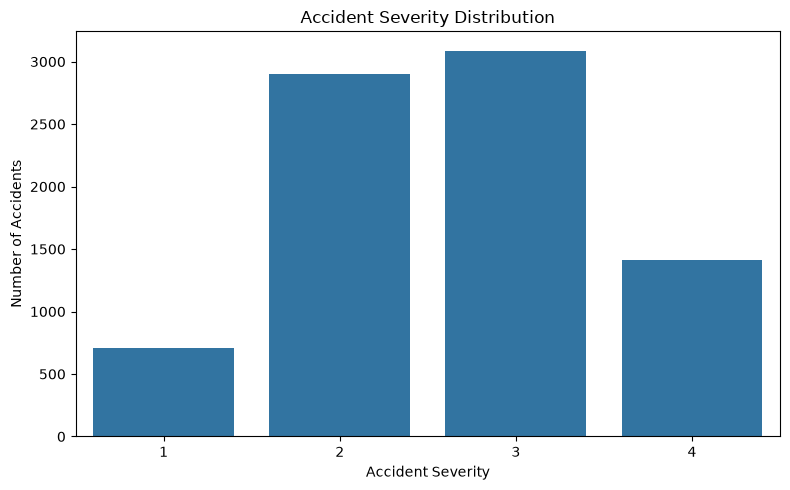

In [17]:
# Plot severity distribution
if len(severity_candidates) > 0:
    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x=severity_column
    )

    plt.title("Accident Severity Distribution")
    plt.xlabel("Accident Severity")
    plt.ylabel("Number of Accidents")
    plt.tight_layout()
    plt.show()

# Analyze categorical features

In [18]:
# Number of unique values
unique_counts = df.nunique().sort_values(ascending=False)

print("Number of unique values in each column:")
print(unique_counts)

Number of unique values in each column:
Accident_Location_A_Chainage_km             2569
Date                                        1664
Time_of_Accident                             797
Vehicle_Type_Involved_J_V2                    15
Vehicle_Type_Involved_J_V1                    14
Weather_Conditions_H                          12
Road_Condition_F                               8
Causes_D                                       7
Day_of_Week                                    7
Road_Feature_E                                 4
Accident_Severity_C                            4
Accident_Location_A                            2
Accident_Location_A_Chainage_km_RoadSide       2
dtype: int64


In [19]:
# 10 most common values for each categorical column.
for column in categorical_columns:
    print("\n" + "=" * 60)
    print("Column:", column)
    print(df[column].value_counts(dropna=False).head(10))


Column: Date
Date
13/07/2022    22
16/12/2017    20
6/7/2022      20
18/06/2022    20
8/6/2022      20
17/06/2016    18
20/07/2022    18
16/07/2022    18
9/7/2022      18
30/06/2015    16
Name: count, dtype: int64

Column: Time_of_Accident
Time_of_Accident
1:30     64
11:30    60
5:30     60
16:30    56
17:30    54
9:30     54
12:30    52
19:30    52
11:00    50
4:30     50
Name: count, dtype: int64


# Numerical Analysis

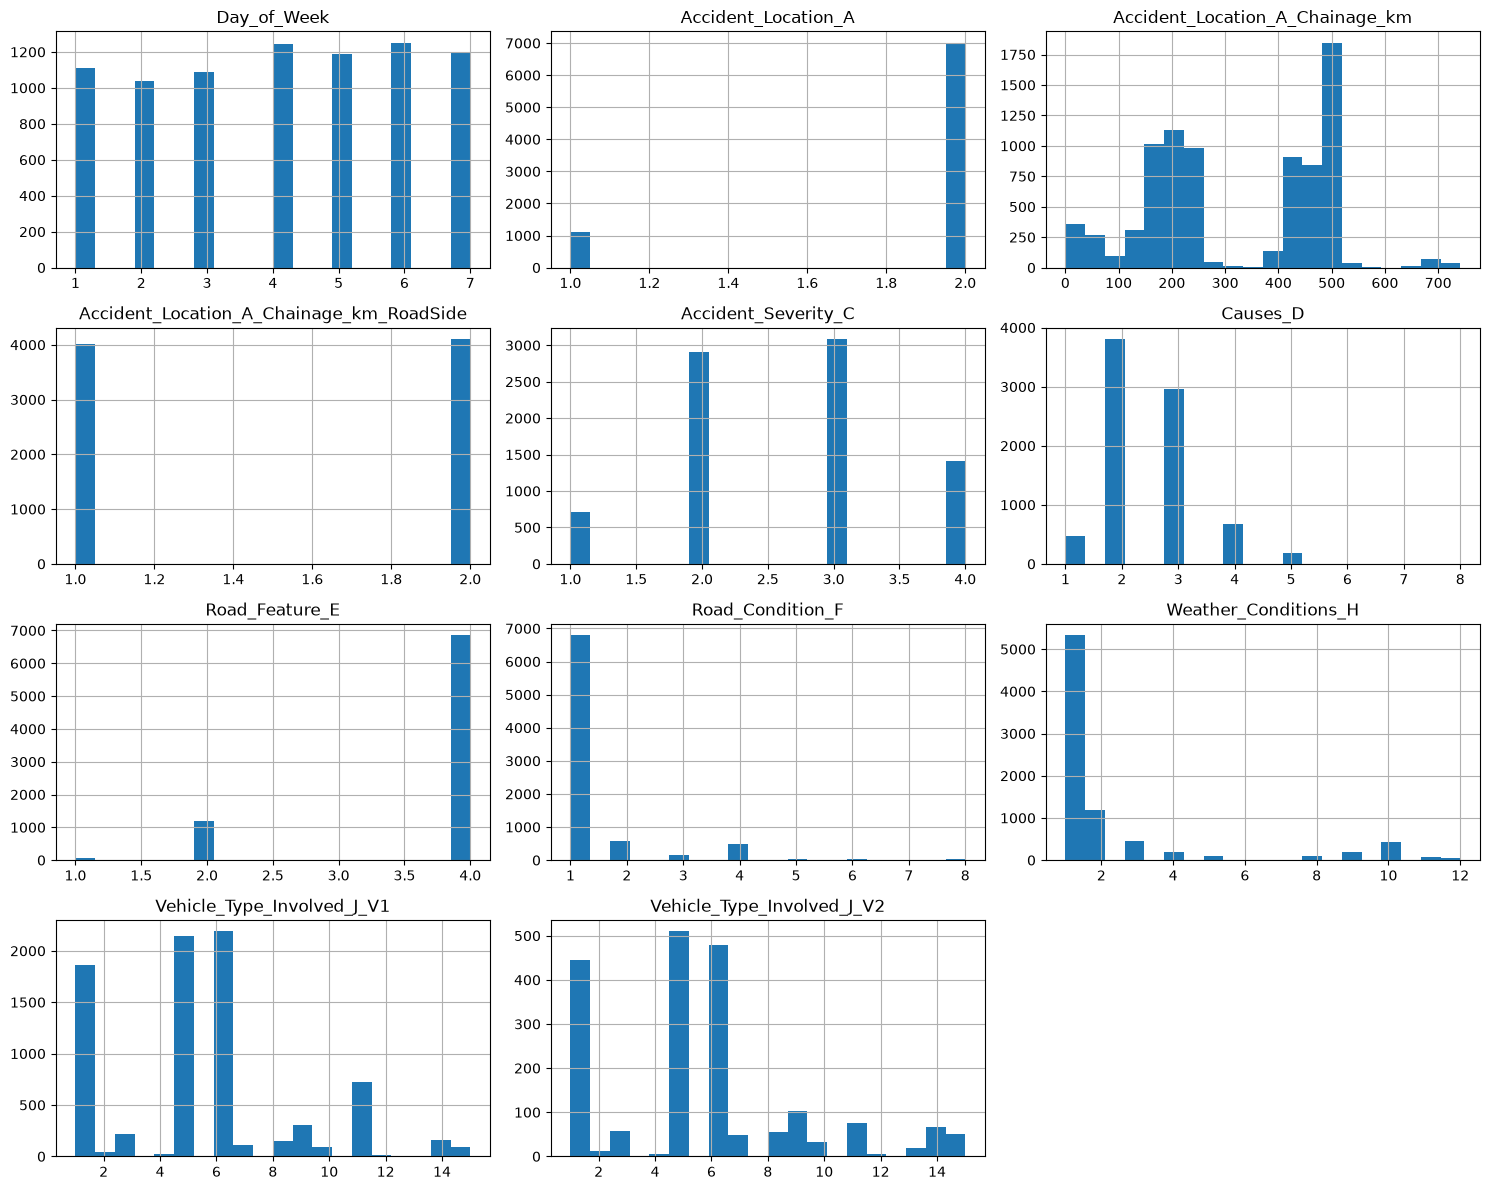

In [20]:
# Numerical Distributions
if len(numeric_columns) > 0:
    df[numeric_columns].hist(
        figsize=(15, 12),
        bins=20
    )

    plt.tight_layout()
    plt.show()

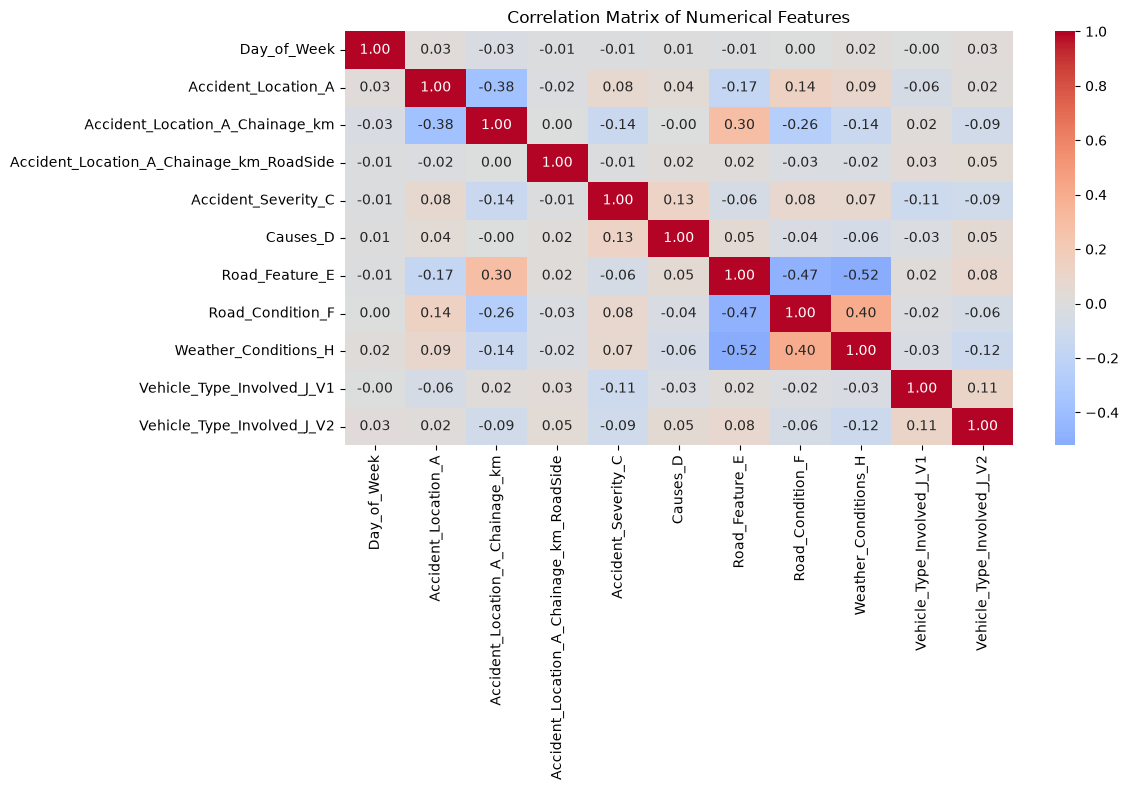

In [21]:
# Correlation Matrix
if len(numeric_columns) > 1:
    correlation_matrix = df[numeric_columns].corr()

    plt.figure(figsize=(12, 8))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0
    )

    plt.title("Correlation Matrix of Numerical Features")
    plt.tight_layout()
    plt.show()

# Location analysis

Because project includes location-based risk visualization, we should check whether the dataset contains geographic information.

In [22]:
# Find location-related columns
location_candidates = [
    column for column in df.columns
    if any(
        word in column.lower()
        for word in [
            "latitude",
            "longitude",
            "location",
            "district",
            "state",
            "city",
            "highway",
            "road"
        ]
    )
]

print("Possible location-related columns:")
print(location_candidates)

Possible location-related columns:
['Accident_Location_A', 'Accident_Location_A_Chainage_km', 'Accident_Location_A_Chainage_km_RoadSide', 'Road_Feature_E', 'Road_Condition_F']


# Weather analysis

Synopsis specifically includes real-time weather, so we should see whether the historical dataset also contains weather-related information.

In [23]:
# Find weather-related columns
weather_candidates = [
    column for column in df.columns
    if any(
        word in column.lower()
        for word in [
            "weather",
            "rain",
            "fog",
            "wind",
            "temperature",
            "visibility",
            "humidity"
        ]
    )
]

print("Possible weather-related columns:")
print(weather_candidates)

Possible weather-related columns:
['Weather_Conditions_H']


# Time-related analysis

In [24]:
# Find time/date columns
time_candidates = [
    column for column in df.columns
    if any(
        word in column.lower()
        for word in [
            "date",
            "time",
            "year",
            "month",
            "hour",
            "day"
        ]
    )
]

print("Possible time-related columns:")
print(time_candidates)

Possible time-related columns:
['Date', 'Day_of_Week', 'Time_of_Accident']


# Final dataset summary

In [25]:
# Generate a compact summary
print("=" * 60)
print("DATASET SUMMARY")
print("=" * 60)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())

print("\nNumerical columns:", len(numeric_columns))
print("Categorical columns:", len(categorical_columns))

print("\nColumns with missing values:", df.isnull().any().sum())

print("=" * 60)

DATASET SUMMARY
Rows: 8116
Columns: 13
Duplicate rows: 4063

Numerical columns: 11
Categorical columns: 2

Columns with missing values: 1


In [26]:
# Save the analysis information
print("Data analysis completed successfully.")
print("No preprocessing or data modification has been performed yet.")

Data analysis completed successfully.
No preprocessing or data modification has been performed yet.


In [27]:
# Inspect missing values in every column
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2),
    "Unique_Values": df.nunique()
})

missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

,Missing_Count,Missing_Percentage,Unique_Values
Vehicle_Type_Involved_J_V2,6154,75.83,15
Day_of_Week,0,0.00,7
Time_of_Accident,0,0.00,797
Accident_Location_A,0,0.00,2
Date,0,0.00,1664
Accident_Location_A_Chainage_km,0,0.00,2569
Accident_Location_A_Chainage_km_RoadSide,0,0.00,2
Causes_D,0,0.00,7
Accident_Severity_C,0,0.00,4
Road_Feature_E,0,0.00,4


In [28]:
# Inspect the actual values in important columns
columns_to_check = [
    "Accident_Severity_C",
    "Vehicle_Type_Involved_J_V1",
    "Vehicle_Type_Involved_J_V2",
    "Weather_Conditions_H",
    "Road_Condition_F",
    "Road_Feature_E",
    "Causes_D"
]

for column in columns_to_check:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False).head(15))


--- Accident_Severity_C ---
Accident_Severity_C
3    3088
2    2904
4    1416
1     708
Name: count, dtype: int64

--- Vehicle_Type_Involved_J_V1 ---
Vehicle_Type_Involved_J_V1
6     2190
5     2142
1     1858
11     722
9      304
3      214
14     164
8      146
7      108
15      94
10      92
2       44
4       20
12      18
Name: count, dtype: int64

--- Vehicle_Type_Involved_J_V2 ---
Vehicle_Type_Involved_J_V2
NaN     6154
5.0      510
6.0      478
1.0      444
9.0      102
11.0      76
14.0      66
3.0       58
8.0       56
15.0      50
7.0       48
10.0      32
13.0      18
2.0       12
12.0       6
Name: count, dtype: int64

--- Weather_Conditions_H ---
Weather_Conditions_H
1     5334
2     1198
3      458
10     440
9      190
4      182
8       96
5       88
11      66
12      48
7       14
6        2
Name: count, dtype: int64

--- Road_Condition_F ---
Road_Condition_F
1    6800
2     570
4     490
3     144
5      36
8      34
6      30
7      12
Name: count, dtype: int64
